# Corpus data quality: the file EDGAR told us to download was the wrong one

**What happened.** We downloaded 60 SEC 10-K filings using EDGAR's own
`primaryDocument` field to pick the file. For 12 of them that field pointed at a
**wrapper document** — a cover page whose Item 8 says *"the financial statements are
in a separate exhibit."* The actual balance sheets, income statements and notes were
in a different file we never fetched.

**Why it was dangerous.** Nothing looked broken. HTTP 200. Right company, right
year, plausible size, correct entry in the manifest. Had we gone straight to
building, a question like *"What were Wells Fargo's total deposits in 2025?"* would
have failed — and the natural response is to blame retrieval and spend a week tuning
chunkers, embedders and rerankers. None of it would have helped: the answer was
never in the index.

This notebook shows how the problem was detected and what changed.

In [1]:
import json, os, re, sys
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
from rag.ingest.profile import profile_doc, plain_text

INK, INK2, SURF = "#0b0b0b", "#52514e", "#fcfcfb"
C_AFTER, C_BEFORE = "#2a78d6", "#eb6834"    # validated categorical slots 1-2
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": "#d8d7d2",
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#eceae4", "grid.linewidth": 0.8,
})

metas = [json.loads(l) for l in open("data/raw/manifest.jsonl")]
df = pd.DataFrame([vars(profile_doc(m)) for m in metas])
df["slug"] = [m["doc_id"].split("_")[1] for m in metas]
df["density"] = df.tables / (df.tokens / 10_000)
print(f"{len(df)} documents | {df.tokens.sum():,} tokens | {df.tables.sum():,} tables"
      f" | hollow: {int(df.hollow.sum())}")

60 documents | 15,450,946 tokens | 20,839 tables | hollow: 0


## 1. What changed

`BEFORE_TOKENS` is recorded from the pre-fix run (EDGAR's `primaryDocument`). `AFTER` is
the current corpus, which picks the largest `.htm` in each submission instead.

Only three companies were affected — but all four of their years.

In [2]:
BEFORE_TOKENS = {   # tokens, from the pre-fix manifest
    "wellsfargo": {"2022": 102465, "2023": 96634, "2024": 83543, "2025": 23354},
    "bnymellon":  {"2022":  71839, "2023": 62977, "2024": 62584, "2025": 63162},
    "usbancorp":  {"2022":  60289, "2023": 65924, "2024": 63933, "2025": 66036},
}
rows = []
for slug, years in BEFORE_TOKENS.items():
    for fy, before in years.items():
        after = int(df[(df.slug == slug) & (df.fy == fy)].tokens.iloc[0])
        rows.append({"company": slug, "fy": fy, "before": before, "after": after,
                     "gain": round(after / before, 1)})
change = pd.DataFrame(rows)
change

,company,fy,before,after,gain
0,wellsfargo,2022,102465,237286,2.3
1,wellsfargo,2023,96634,234496,2.4
2,wellsfargo,2024,83543,215589,2.6
3,wellsfargo,2025,23354,265580,11.4
4,bnymellon,2022,71839,210700,2.9
5,bnymellon,2023,62977,219575,3.5
6,bnymellon,2024,62584,224941,3.6
7,bnymellon,2025,63162,212787,3.4
8,usbancorp,2022,60289,224710,3.7
9,usbancorp,2023,65924,158548,2.4


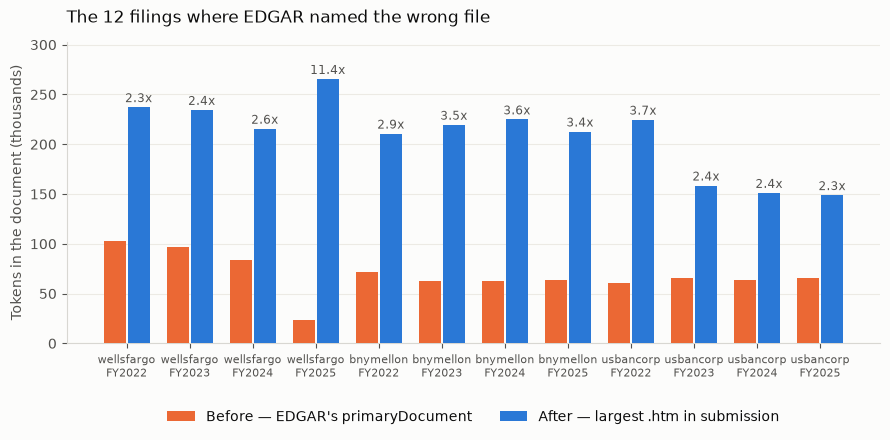

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.6))
labels = [f"{r.company}\nFY{r.fy}" for r in change.itertuples()]
x = range(len(change)); w = 0.38
ax.bar([i - w/2 for i in x], change.before/1000, w-0.03, color=C_BEFORE,
       label="Before — EDGAR's primaryDocument", zorder=3)
ax.bar([i + w/2 for i in x], change.after/1000,  w-0.03, color=C_AFTER,
       label="After — largest .htm in submission", zorder=3)
for i, r in enumerate(change.itertuples()):
    ax.text(i + w/2, r.after/1000 + 5, f"{r.gain}x", ha="center", fontsize=8.5, color=INK2)

ax.set_xticks(list(x)); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Tokens in the document (thousands)")
ax.set_ylim(0, change.after.max()/1000 * 1.14)   # headroom for the multiplier labels
ax.set_title("The 12 filings where EDGAR named the wrong file",
             fontsize=12, color=INK, pad=14, loc="left")
ax.grid(True, axis="y", zorder=0)
# Legend below the axes: inside the plot it sat on top of the first two data labels.
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout(); plt.show()

Wells Fargo FY2025 grew **11.4×**. Its filing had 23,354 tokens — for a top-five
US bank whose peers file 250,000–430,000.

## 2. How it was detected: three signals, three blind spots

Each detector alone got it wrong. Only together do they cover the corpus.

In [4]:
detectors = pd.DataFrame([
    {"detector": "Text pattern (Item 8 → elsewhere)",
     "caught": "US Bancorp, BNY Mellon, WFC 22-24",
     "missed": "WFC FY2025 — never uses the phrase",
     "false positive": "Capital One — matched its table of contents (501 tables!)"},
    {"detector": "Table density < 8 per 10k tokens",
     "caught": "All the hollow filers",
     "missed": "WFC FY2025 — 40 tables / 23k tok reads as HIGH density",
     "false positive": "none"},
    {"detector": "Peer-relative size vs same company's other years",
     "caught": "WFC FY2025 (23k vs its own 97k median)",
     "missed": "none",
     "false positive": "none"},
]).set_index("detector")
pd.set_option("display.max_colwidth", 60)
detectors

,caught,missed,false positive
detector,,,
Text pattern (Item 8 → elsewhere),"US Bancorp, BNY Mellon, WFC 22-24",WFC FY2025 — never uses the phrase,Capital One — matched its table of contents (501 tables!)
Table density < 8 per 10k tokens,All the hollow filers,WFC FY2025 — 40 tables / 23k tok reads as HIGH density,none
Peer-relative size vs same company's other years,WFC FY2025 (23k vs its own 97k median),none,none


**The rules this gives you**

- When a cheap textual signal and a structural measurement disagree, trust the
  measurement and treat the disagreement as a bug in your detector.
- Absolute thresholds cannot catch what peer-relative comparison can. Adjacent years
  of the same filer are the tightest control available.
- No single signal is sufficient. That is the lesson — not any particular threshold.

## 3. Why a name-based rule could never have worked

Every filing has two HTML documents sharing a stem, `X.htm` and `X_d2.htm`. Which
one holds the content is not predictable from the name — **Wells Fargo's convention
inverted between consecutive years:**

```
FY2025:  EDGAR named wfc-20251231_d2.htm  (360 KB)  →  real content wfc-20251231.htm     (11.6 MB)
FY2024:  EDGAR named wfc-20241231.htm               →  real content wfc-20241231_d2.htm  (10.9 MB)
```

And US Bancorp's FY2022 went through a filing agent, so the names share no
convention at all: `d410791d10k.htm` (1.0 MB) vs `d410791dex13.htm` (**6.7 MB**).

An intermediate version of the fix required the candidate to share the primary's
filename stem — and silently failed on exactly that filing. The final rule is
simply **largest `.htm`, excluding `R\d+.htm` XBRL viewer renderings**, verified
afterwards by the profiler.

> Prefer a simple rule plus a verification pass over a complicated rule you have to trust.

## 4. The corpus now

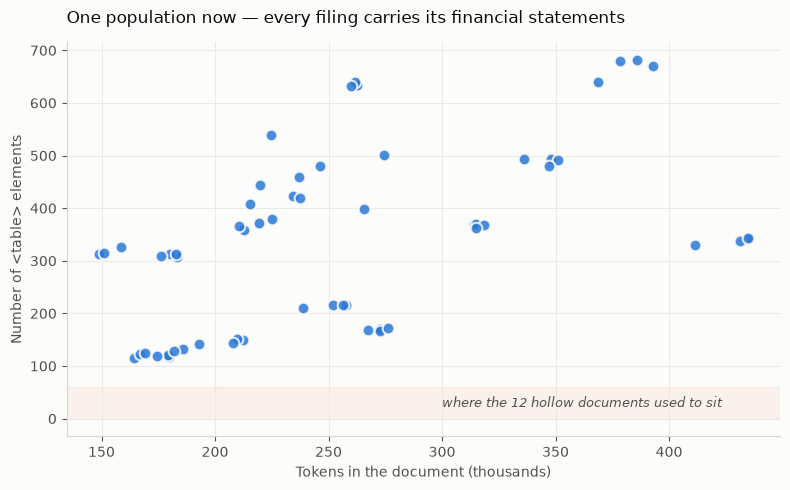

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df.tokens/1000, df.tables, s=70, c=C_AFTER, alpha=.85,
           edgecolors=SURF, linewidths=1.5, zorder=3)
ax.axhspan(0, 60, color=C_BEFORE, alpha=.07, zorder=1)
ax.text(300, 22, "where the 12 hollow documents used to sit",
        color=INK2, fontsize=9, style="italic")
ax.set_xlabel("Tokens in the document (thousands)")
ax.set_ylabel("Number of <table> elements")
ax.set_title("One population now — every filing carries its financial statements",
             fontsize=12, color=INK, pad=14, loc="left")
ax.grid(True, zorder=0)
plt.tight_layout(); plt.show()

In [6]:
summary = pd.DataFrame({
    "before": {"documents": 60, "tokens": 13_769_432, "tables": 16_655,
               "min tokens": 23_354, "hollow": 12},
    "after":  {"documents": len(df), "tokens": int(df.tokens.sum()),
               "tables": int(df.tables.sum()), "min tokens": int(df.tokens.min()),
               "hollow": int(df.hollow.sum())},
})
summary

,before,after
documents,60,60
tokens,13769432,15450946
tables,16655,20839
min tokens,23354,148914
hollow,12,0


## 5. The takeaway

In RAG, **a data problem and a retrieval problem produce the identical symptom** — a
bad answer. Distinguishing them after the pipeline exists is expensive; checking the
data first is cheap.

This is also the fourth silent-under-delivery bug in this corpus work. The others: a
scan reporting zero dollar amounts in a bank's annual report, a size filter that
would have rejected every large bank, and a filing enumerator returning 1 document
when asked for 4. **None raised an exception.** Every one returned plausible-looking
*less*.

That is the characteristic failure mode of data pipelines, and it is why
`rag corpus profile` runs before anything gets indexed.

**Still open:** the corpus is entirely EDGAR HTML. Phase 2's hard parsing problems —
scanned pages, multi-column layout, tables drawn as positioned glyphs — need PDF
sources (RBI circulars, OCC handbooks, annual reports) and no SEC dataset has them.